# ColdCard
## Exercice 1

In [1]:
import tarfile

with tarfile.open("blocos.tgz", "r:gz") as t:
    for i, m in enumerate(t):
        print(m.name, m.size)
        if i >= 19:        # only the first 20 entries
            break

00000000000000000000197fc747ebee54c64dd263e9e00c4e88902165085e57 17513238
000000000000000000001fe75085bf50293dc0067d19450e06a1116e57504b51 16015576
000000000000000000002066fc153d8aac1c83d80e8d292753d12e23b44f106e 15766632
0000000000000000000027608332da0b71948453b4d27cb01727b679ff3f7fb6 16367062
0000000000000000000028b7acc2f52617a87a907341943963441908fe8eafbf 17536165
000000000000000000002a5f6037acd9d3583ba305c487a8d3d8bef3c47606bf 16360866
000000000000000000003094b4c6bfd6caa47f12985b8b78a54c7524dd1bc606 17576661
0000000000000000000035d9248bcd01daff93536ad017ef75790fbcfe1d14e3 15545270
0000000000000000000036280662bcd3729c066c592b69095e5a61718b248313 16451519
000000000000000000003fc24e038d716615778638f9bb43c5c415d0662341f7 16452426
0000000000000000000040ac89ff7d6f977538f5d471a67b4f0975e38db96055 16249945
00000000000000000000432a39c63936ce4e8157ef6ccfced25b87e1f03150be 16622738
000000000000000000004e33b4c5e97dd588954fcae7545a92961c4cf5e42c9f 16799793
0000000000000000000054f75c544c412cd99f

In [2]:
with tarfile.open("blocos.tgz", "r:gz") as t:
    for m in t:
        if m.isfile():
            data = t.extractfile(m).read(300)
            print(m.name, m.size)
            print(data[:80].hex())    # first 80 bytes in hexadecimal
            print(data[:200])         # and as raw text
            break

00000000000000000000197fc747ebee54c64dd263e9e00c4e88902165085e57 17513238
7b0a202020202268617368223a20223030303030303030303030303030303030303030313937666337343765626565353463363464643236336539653030633465383839303231363530383565353722
b'{\n    "hash": "00000000000000000000197fc747ebee54c64dd263e9e00c4e88902165085e57",\n    "ver": 537001984,\n    "prev_block": "0000000000000000000160d2e0b5aea497c51d8a70fd4aa86a4e6c116884c164",\n    "mrkl_'


In [3]:
import os, tarfile

print(os.path.getsize("blocos.tgz") / 1e6, "MB")

n = total = 0
with tarfile.open("blocos.tgz", "r:gz") as t:
    for m in t:
        if m.isfile():
            n += 1
            total += m.size
print(n, "blocks;", round(total / 1e9, 2), "GB uncompressed")

207.43607 MB
98 blocks; 1.64 GB uncompressed


In [4]:
import json

with tarfile.open("blocos.tgz", "r:gz") as t:
    for m in t:
        if m.isfile():
            blk = json.load(t.extractfile(m))
            break

print(list(blk.keys()))
print(blk.get("n_tx"), len(blk["tx"]), blk.get("height"), blk.get("time"))

tx = blk["tx"][1]            # index 0 is the coinbase (it has no real inputs)
print(list(tx.keys()))
print(list(tx["inputs"][0].keys()))
print(list((tx["inputs"][0].get("prev_out") or {}).keys()))
print(list(tx["out"][0].keys()))

['hash', 'ver', 'prev_block', 'mrkl_root', 'time', 'bits', 'next_block', 'fee', 'nonce', 'n_tx', 'size', 'block_index', 'main_chain', 'height', 'weight', 'tx']
5871 5871 960185 1785375168
['hash', 'ver', 'vin_sz', 'vout_sz', 'size', 'weight', 'fee', 'relayed_by', 'lock_time', 'tx_index', 'double_spend', 'time', 'block_index', 'block_height', 'inputs', 'out']
['sequence', 'witness', 'script', 'index', 'prev_out']
['type', 'spent', 'value', 'spending_outpoints', 'n', 'tx_index', 'script', 'addr']
['type', 'spent', 'value', 'spending_outpoints', 'n', 'tx_index', 'script', 'addr']


In [5]:
import tarfile, json, os
import pandas as pd

COLLECT = "bc1qnk4zh9qcnap2mycp56qjrgza3cc8ylrh8fecp0"

tx_rows, in_rows, out_rows = [], [], []
with tarfile.open("blocos.tgz", "r:gz") as t:
    for m in t:
        if not m.isfile():
            continue
        blk = json.load(t.extractfile(m))
        h = blk["height"]
        for tx in blk["tx"]:
            th = tx["hash"]
            tx_rows.append((th, h, tx.get("time"), tx.get("fee"), tx["size"],
                            tx["weight"], tx["vin_sz"], tx["vout_sz"],
                            tx["lock_time"], tx["ver"]))
            for i, vin in enumerate(tx["inputs"]):
                po = vin.get("prev_out")
                if po is None:              # coinbase: no previous output
                    continue
                in_rows.append((th, i, vin["sequence"], po.get("addr"),
                                po["value"], po.get("type"), po["tx_index"], po["n"]))
            for o in tx["out"]:
                out_rows.append((th, o["n"], o.get("addr"), o["value"],
                                 o.get("type"), o.get("spent")))

txs = pd.DataFrame(tx_rows, columns=["txid", "height", "time", "fee", "size",
                                     "weight", "n_in", "n_out", "lock_time", "ver"])
ins = pd.DataFrame(in_rows, columns=["txid", "idx", "sequence", "addr", "value",
                                     "type", "prev_tx_index", "prev_n"])
outs = pd.DataFrame(out_rows, columns=["txid", "n", "addr", "value", "type", "spent"])

os.makedirs("data", exist_ok=True)
txs.to_pickle("data/txs.pkl"); ins.to_pickle("data/ins.pkl"); outs.to_pickle("data/outs.pkl")
print(txs.shape, ins.shape, outs.shape)
print(txs["height"].min(), txs["height"].max())

(493571, 10) (778830, 8) (1085654, 6)
960179 960802


In [6]:
sum_in  = ins.groupby("txid")["value"].sum()
sum_out = outs.groupby("txid")["value"].sum()
chk = txs.set_index("txid").join(sum_in.rename("sum_in")).join(sum_out.rename("sum_out"))
chk = chk[chk["sum_in"].notna()]                       # drop coinbase transactions
bad = chk[(chk["sum_in"] - chk["sum_out"]) != chk["fee"]]
print(len(chk), len(bad))
print(txs["txid"].is_unique)

493571 98
True


In [7]:
print(bad[["sum_in", "sum_out", "fee"]].head())

first_tx = set(txs.groupby("height")["txid"].first())    # first transaction of each block
print(bad.index.isin(first_tx).all(), (bad["sum_in"] == 0).all(), len(bad))

                                                    sum_in    sum_out  fee
txid                                                                      
ca6f2cc5f30c12c27d3397facf2a440f7630544ce3ea9d7...       0  315939895    0
28fceb80613fd53925fafecb53cbe144d83a0d229c7db98...       0  315028459    0
693d2773c9a9c734b1cba2e1323871dafd4b8bb7e7effd0...       0  316678966    0
56d8515c8479a985530b29fac6b347fc0b838c68dedd39b...       0  313150009    0
0ba0fb28f54754441543d296f178799b74a895d4d8ae518...       0  313111756    0
True True 98


In [8]:
cb = set(bad.index)
txs["is_coinbase"] = txs["txid"].isin(cb)
ins = ins[~ins["txid"].isin(cb)].copy()

sum_in  = ins.groupby("txid")["value"].sum()
sum_out = outs.groupby("txid")["value"].sum()
chk = txs[~txs["is_coinbase"]].set_index("txid").join(sum_in.rename("sum_in")).join(sum_out.rename("sum_out"))
print(len(chk), ((chk["sum_in"] - chk["sum_out"]) != chk["fee"]).sum())

txs.to_pickle("data/txs.pkl"); ins.to_pickle("data/ins.pkl")

493473 0


In [9]:
# make sure COLLECT contains your address
paid = outs[outs["addr"] == COLLECT]
print(len(paid), paid["txid"].nunique(), paid["value"].sum() / 1e8)

# does the collection address also SPEND anything in these blocks?
print((ins["addr"] == COLLECT).sum())

# which blocks, and how many inputs do these transactions have?
pt = txs[txs["txid"].isin(paid["txid"])]
print(pt["height"].min(), pt["height"].max())
print(pt["n_in"].describe())

504 504 594.47725695
341
960188 960793
count    504.000000
mean       2.636905
std       11.324120
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max      200.000000
Name: n_in, dtype: float64


In [10]:
collect_spends = set(ins.loc[ins["addr"] == COLLECT, "txid"])   # transactions that spend from COLLECT
paid_tx = set(paid["txid"])

self_tx   = paid_tx & collect_spends        # pay COLLECT and spend from it
inflow_tx = paid_tx - collect_spends        # pay COLLECT, spend from others only

print(len(collect_spends), len(self_tx), len(inflow_tx))

inflow = paid[paid["txid"].isin(inflow_tx)]
print(inflow["value"].sum() / 1e8)                 # BTC paid to COLLECT by inflow transactions
print(txs[txs["txid"].isin(inflow_tx)]["n_out"].value_counts().head())   # how many outputs these have

1 0 504
594.47725695
n_out
1    501
3      2
2      1
Name: count, dtype: int64


In [11]:
victim_ins = ins[ins["txid"].isin(inflow_tx)].copy()

print(len(victim_ins))                                                  # inputs = UTXOs spent
print(victim_ins[["prev_tx_index", "prev_n"]].drop_duplicates().shape[0])  # unique UTXOs (should match)
print(victim_ins["addr"].nunique(), victim_ins["addr"].isna().sum())    # distinct addresses, missing addresses
print(victim_ins["value"].sum() / 1e8)                                  # total value of the stolen inputs
print(txs[txs["txid"].isin(inflow_tx)]["fee"].sum() / 1e8)              # total fees paid
print(victim_ins["type"].value_counts())                                # address / script types

stolen_by_addr = victim_ins.groupby("addr")["value"].sum().sort_values(ascending=False)
print(stolen_by_addr.describe())
print((stolen_by_addr / 1e8).head(5))

1329
1329
504 0
594.51489212
0.03659231
type
0    1329
Name: count, dtype: int64
count    5.040000e+02
mean     1.179593e+08
std      2.556898e+08
min      1.092000e+03
25%      2.380571e+07
50%      4.064882e+07
75%      9.999975e+07
max      2.989253e+09
Name: value, dtype: float64
addr
bc1qe85jr4em79p66fsszkvfhwjf6p6qst58a2ahlr    29.892525
bc1qvshd3nv6mjjs5wtk6x5ekppakdp2trqcsdvwlf    24.082193
bc1q30363smzw6uk5n2znj65mf9432s0e3d92e3fu5    14.429975
bc1q9qaljdxux9nr4uuyh8v7khvk7hgvpku5e0xyjj    14.252021
bc1qgzxfgqgvnle9p6kksk35t54ycu2tx2hwau5ppw    11.738049
Name: value, dtype: float64


In [12]:
import numpy as np

def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    return (2 * np.sum(np.arange(1, n + 1) * x)) / (n * x.sum()) - (n + 1) / n

print(gini([1, 1, 1, 1]), gini([0, 0, 0, 1]))   # should print 0.0 and 0.75

0.0 0.75


In [13]:
spent_all    = ins.groupby("addr")["value"].sum()                                   # everyone in the blocks
spent_others = ins[~ins["txid"].isin(inflow_tx)].groupby("addr")["value"].sum()     # without the victims

print(len(stolen_by_addr), gini(stolen_by_addr.values))
print(len(spent_all),      gini(spent_all.values))
print(len(spent_others),   gini(spent_others.values))

504 0.6663149401156394
304569 0.9945980847733527
304065 0.9946905544791369


In [14]:
rng = np.random.default_rng(0)
vals = spent_others.values
gs = [gini(rng.choice(vals, 504, replace=False)) for _ in range(1000)]
print(np.mean(gs), np.percentile(gs, [2.5, 97.5]))

0.9624905066139781 [0.92047699 0.99671001]


In [15]:
from scipy import stats

exp = np.log10(1 + 1 / np.arange(1, 10))

def first_digit(v):
    v = np.asarray(v, dtype=np.int64)
    v = v[v > 0]
    return np.array([int(str(x)[0]) for x in v])

def benford(values):
    d = first_digit(values)
    counts = np.bincount(d, minlength=10)[1:]
    obs = counts / len(d)
    mad = np.abs(obs - exp).mean()
    chi, p = stats.chisquare(counts, f_exp=exp * len(d))
    return obs, mad, chi, p, len(d)

stolen_vals = victim_ins["value"]
other_vals  = ins.loc[~ins["txid"].isin(inflow_tx), "value"]

print("expected", np.round(exp, 3))
for name, v in [("stolen", stolen_vals), ("others", other_vals)]:
    obs, mad, chi, p, n = benford(v)
    print(name, n, "MAD", round(mad, 4), "chi2", round(chi, 1), "p", p)
    print(np.round(obs, 3))

expected [0.301 0.176 0.125 0.097 0.079 0.067 0.058 0.051 0.046]
stolen 1329 MAD 0.0428 chi2 225.0 p 3.411062128902341e-44
[0.419 0.223 0.076 0.047 0.105 0.068 0.022 0.017 0.022]
others 777403 MAD 0.0101 chi2 12868.0 p 0.0
[0.303 0.152 0.141 0.096 0.103 0.07  0.055 0.039 0.04 ]


In [16]:
lv = np.log10(stolen_vals[stolen_vals > 0])
lo = np.log10(other_vals[other_vals > 0])
print(np.percentile(lv, [5, 25, 50, 75, 95]).round(2), lv.std().round(2))
print(np.percentile(lo, [5, 25, 50, 75, 95]).round(2), lo.std().round(2))

[5.   5.78 6.36 7.42 8.26] 1.27
[2.58 4.2  4.8  5.61 7.18] 1.27


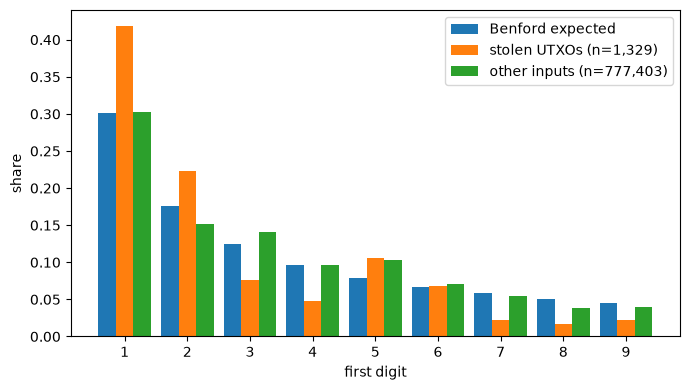

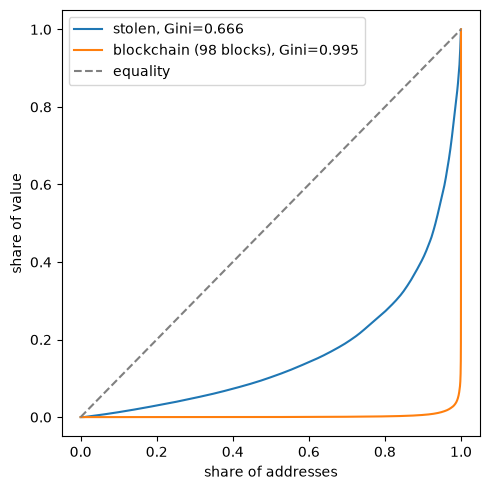

In [17]:
import matplotlib.pyplot as plt, os
os.makedirs("figures", exist_ok=True)

digits = np.arange(1, 10)
o_s = benford(stolen_vals)[0]
o_o = benford(other_vals)[0]
w = 0.28
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(digits - w, exp, w, label="Benford expected")
ax.bar(digits,     o_s, w, label="stolen UTXOs (n=1,329)")
ax.bar(digits + w, o_o, w, label="other inputs (n=777,403)")
ax.set_xlabel("first digit"); ax.set_ylabel("share"); ax.set_xticks(digits); ax.legend()
fig.tight_layout(); fig.savefig("figures/benford.png", dpi=200)

def lorenz(x):
    x = np.sort(np.asarray(x, float))
    c = np.cumsum(x) / x.sum()
    return np.linspace(0, 1, len(x) + 1), np.insert(c, 0, 0)

fig, ax = plt.subplots(figsize=(5, 5))
for name, v in [("stolen", stolen_by_addr.values), ("blockchain (98 blocks)", spent_all.values)]:
    p, c = lorenz(v)
    ax.plot(p, c, label=f"{name}, Gini={gini(v):.3f}")
ax.plot([0, 1], [0, 1], "--", color="gray", label="equality")
ax.set_xlabel("share of addresses"); ax.set_ylabel("share of value"); ax.legend()
fig.tight_layout(); fig.savefig("figures/lorenz.png", dpi=200)

In [18]:
dec = np.floor(np.log10(stolen_vals)).astype(int)
fd = stolen_vals.astype(str).str[0].astype(int)
print(stolen_vals.groupby(dec).size())
print(pd.crosstab(dec, fd))

value
2     40
3      2
4     12
5    368
6    387
7    396
8    114
9     10
Name: value, dtype: int64
value    1    2   3   4   5   6   7   8   9
value                                      
2        0   22  15   0   2   0   0   0   1
3        0    1   0   0   0   0   0   0   1
4        3    1   0   2   3   0   0   1   2
5      206    4   0   2  68  62   9  10   7
6      197  111  28   9  26   4   5   3   4
7       82  134  52  44  33  21  11   7  12
8       61   21   6   6   8   4   4   2   2
9        8    2   0   0   0   0   0   0   0


## Exercice 2

In [19]:
print(len(inflow_tx), txs.shape, ins.shape)

504 (493571, 11) (778732, 8)


In [20]:
# the theft set (reuse the earlier variable if it exists)
theft = inflow_tx if "inflow_tx" in globals() else theft

tx_ml = txs[~txs["is_coinbase"]].copy()             # coinbase: no real inputs, never theft

g = ins.groupby("txid")
ins["is_bc1q"] = ins["addr"].str.startswith("bc1q")
f_in = pd.DataFrame({
    "in_sum":   g["value"].sum(),
    "in_mean":  g["value"].mean(),
    "in_min":   g["value"].min(),
    "in_max":   g["value"].max(),
    "in_std":   g["value"].std().fillna(0),
    "in_n_addr": g["addr"].nunique(),
    "in_share_bc1q": ins.groupby("txid")["is_bc1q"].mean(),
    "seq_min":  g["sequence"].min(),
    "seq_max":  g["sequence"].max(),
})

o = outs.groupby("txid")["value"]
f_out = pd.DataFrame({"out_share_max": o.max() / o.sum()})   # share of the largest output

df = tx_ml.set_index("txid")[["n_in", "n_out", "size", "weight", "fee", "lock_time", "ver"]]
df = df.join(f_in).join(f_out)
df["fee_rate"] = df["fee"] / (df["weight"] / 4)              # satoshis per virtual byte
df["y"] = df.index.isin(theft).astype(int)

print(df.shape, df["y"].sum(), round(df["y"].mean(), 5))
print(df.isna().sum().sum())
print(df.groupby("y")[["n_in", "n_out", "in_sum", "fee_rate", "out_share_max"]].median())

(493473, 19) 504 0.00102
222
   n_in  n_out      in_sum   fee_rate  out_share_max
y                                                   
0   1.0    2.0     48592.0   0.445242            1.0
1   1.0    1.0  40648820.0  30.136986            1.0


In [21]:
print(df.isna().sum()[lambda s: s > 0])
print(df[df.isna().any(axis=1)][["n_in", "n_out", "in_sum", "fee", "out_share_max"]].head())

out_share_max    222
dtype: int64
                                                    n_in  n_out  in_sum  fee  \
txid                                                                           
1ca7b1e052c12464764698d2ca3a717382e0025b9b7ef9c...     1      1     746  746   
a83e4d185adec4ceb1f3c0b99605aa149c547e6ce765183...     1      1     710  710   
9b1ea191de1c22318ae694d2b330ef63b170e7be5aa8051...     1      1     474  474   
dbc5ddfec363f91244b2cf466a54d57c34627a6eb445a81...     1      1     474  474   
57e182987aee077880d38cc82809d62e4ecd1a2e2f70ee7...     1      1     330  330   

                                                    out_share_max  
txid                                                               
1ca7b1e052c12464764698d2ca3a717382e0025b9b7ef9c...            NaN  
a83e4d185adec4ceb1f3c0b99605aa149c547e6ce765183...            NaN  
9b1ea191de1c22318ae694d2b330ef63b170e7be5aa8051...            NaN  
dbc5ddfec363f91244b2cf466a54d57c34627a6eb445a81...            NaN

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

X = df.drop(columns="y")
y = df["y"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)
print(X_train.shape, X_test.shape, y_train.sum(), y_test.sum())

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred = dummy.predict(X_test)
print(accuracy_score(y_test, pred), recall_score(y_test, pred))
print(confusion_matrix(y_test, pred))

(345431, 18) (148042, 18) 353 151
0.9989800191837451 0.0
[[147891      0]
 [   151      0]]


In [23]:
# 1. check, then fill the 222 missing values and redo the split
print(df.loc[df["out_share_max"].isna(), "y"].sum())        # expect 0 thefts among them
df["out_share_max"] = df["out_share_max"].fillna(0)

from sklearn.model_selection import train_test_split
X = df.drop(columns="y"); y = df["y"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

# 2. models
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score

models = {
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "tree":   DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "forest": RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                     n_jobs=-1, random_state=42),
}

results = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    results[name] = (m, pred, proba)
    print("=====", name)
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, digits=3))
    print("ROC AUC", round(roc_auc_score(y_test, proba), 4),
          "PR AUC", round(average_precision_score(y_test, proba), 4))

0
===== logreg
[[146940    951]
 [     1    150]]
              precision    recall  f1-score   support

           0      1.000     0.994     0.997    147891
           1      0.136     0.993     0.240       151

    accuracy                          0.994    148042
   macro avg      0.568     0.993     0.618    148042
weighted avg      0.999     0.994     0.996    148042

ROC AUC 0.9971 PR AUC 0.1473
===== tree
[[147754    137]
 [     1    150]]
              precision    recall  f1-score   support

           0      1.000     0.999     1.000    147891
           1      0.523     0.993     0.685       151

    accuracy                          0.999    148042
   macro avg      0.761     0.996     0.842    148042
weighted avg      1.000     0.999     0.999    148042

ROC AUC 0.9962 PR AUC 0.5228
===== forest
[[147809     82]
 [    63     88]]
              precision    recall  f1-score   support

           0      1.000     0.999     1.000    147891
           1      0.518     0.583  

In [24]:
from sklearn.tree import export_text

tree = results["tree"][0]
print(export_text(tree, feature_names=list(X.columns), max_depth=4))
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(8))

# what do the tree's false alarms look like compared with its true hits?
pred_t = results["tree"][1]
fp = X_test[(pred_t == 1) & (y_test == 0)]
tp = X_test[(pred_t == 1) & (y_test == 1)]
cols = ["n_in", "n_out", "in_sum", "fee_rate", "in_share_bc1q", "seq_min", "in_n_addr"]
print(len(fp), len(tp))
print(pd.concat([fp[cols].median().rename("false_alarm"),
                 tp[cols].median().rename("true_theft")], axis=1))

|--- fee_rate <= 30.04
|   |--- lock_time <= 960731.50
|   |   |--- n_in <= 1.50
|   |   |   |--- class: 0
|   |   |--- n_in >  1.50
|   |   |   |--- in_sum <= 1097.00
|   |   |   |   |--- in_min <= 510.00
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- in_min >  510.00
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- in_sum >  1097.00
|   |   |   |   |--- n_in <= 2.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- n_in >  2.50
|   |   |   |   |   |--- class: 0
|   |--- lock_time >  960731.50
|   |   |--- n_out <= 2.50
|   |   |   |--- size <= 151.50
|   |   |   |   |--- class: 0
|   |   |   |--- size >  151.50
|   |   |   |   |--- class: 0
|   |   |--- n_out >  2.50
|   |   |   |--- in_sum <= 94604.00
|   |   |   |   |--- out_share_max <= 0.95
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- out_share_max >  0.95
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- in_sum >  94604.00
|   |   |   |   |--- seq_max <= 1073741824.

In [25]:
fp_out = outs[outs["txid"].isin(fp.index)]
vc = fp_out["addr"].value_counts()
print(len(fp), fp_out["addr"].nunique(), vc.head(5).values)     # how many distinct destinations?

h = txs.set_index("txid")["height"]
print(h.loc[fp.index].describe())                               # when did the false alarms happen?
print(h.loc[tp.index].describe())                               # and the true thefts

print(fp["fee_rate"].round(3).value_counts().head(5))           # exact fee rates
print(tp["fee_rate"].round(3).value_counts().head(5))

137 15 [120   8   1   1   1]
count       137.000000
mean     960223.189781
std         145.145947
min      960183.000000
25%      960185.000000
50%      960185.000000
75%      960185.000000
max      960802.000000
Name: height, dtype: float64
count       150.000000
mean     960189.933333
std           1.046994
min      960188.000000
25%      960189.000000
50%      960190.000000
75%      960191.000000
max      960191.000000
Name: height, dtype: float64
fee_rate
30.206    61
30.137    57
30.088     2
30.127     2
2.255      1
Name: count, dtype: int64
fee_rate
30.206    64
30.137    63
30.127     3
30.085     3
30.169     3
Name: count, dtype: int64


In [26]:
from sklearn.model_selection import StratifiedKFold, cross_validate

feat = [c for c in X.columns if c != "lock_time"]          # lock_time acts as a timestamp
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"precision": "precision", "recall": "recall", "f1": "f1", "pr_auc": "average_precision"}

for name, m in models.items():
    r = cross_validate(m, X[feat], y, cv=cv, scoring=scoring, n_jobs=1)
    print(name, {k: (round(r[f"test_{k}"].mean(), 3), round(r[f"test_{k}"].std(), 3)) for k in scoring})

logreg {'precision': (np.float64(0.14), np.float64(0.008)), 'recall': (np.float64(0.992), np.float64(0.007)), 'f1': (np.float64(0.245), np.float64(0.011)), 'pr_auc': (np.float64(0.154), np.float64(0.005))}
tree {'precision': (np.float64(0.528), np.float64(0.048)), 'recall': (np.float64(0.982), np.float64(0.008)), 'f1': (np.float64(0.686), np.float64(0.042)), 'pr_auc': (np.float64(0.529), np.float64(0.027))}
forest {'precision': (np.float64(0.537), np.float64(0.023)), 'recall': (np.float64(0.615), np.float64(0.052)), 'f1': (np.float64(0.573), np.float64(0.032)), 'pr_auc': (np.float64(0.522), np.float64(0.022))}


In [28]:
from sklearn.model_selection import GridSearchCV

Xtr, Xte = X_train[feat], X_test[feat]

grid_tree = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=42),
    {"max_depth": [3, 4, 6, 8, 12], "min_samples_leaf": [1, 5, 20, 100]},
    scoring="average_precision", cv=5, n_jobs=-1)
grid_tree.fit(Xtr, y_train)
print(grid_tree.best_params_, round(grid_tree.best_score_, 3))

grid_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                           n_jobs=-1, random_state=42),
    {"max_depth": [8, 12], "min_samples_leaf": [5, 20]},
    scoring="average_precision", cv=3)
grid_rf.fit(Xtr, y_train)
print(grid_rf.best_params_, round(grid_rf.best_score_, 3))

{'max_depth': 12, 'min_samples_leaf': 20} 0.587
{'max_depth': 8, 'min_samples_leaf': 20} 0.6


In [29]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

final = {}
for name, est in [("tree", grid_tree.best_estimator_), ("forest", grid_rf.best_estimator_)]:
    oof = cross_val_predict(est, Xtr, y_train, cv=5, method="predict_proba")[:, 1]
    p, r, t = precision_recall_curve(y_train, oof)
    f1 = 2 * p * r / (p + r + 1e-12)
    thr = t[np.argmax(f1[:-1])]
    est.fit(Xtr, y_train)
    proba = est.predict_proba(Xte)[:, 1]
    pred = (proba >= thr).astype(int)
    final[name] = (est, thr, proba, pred)
    print("=====", name, "threshold", round(thr, 3))
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, digits=3))
    print("PR AUC", round(average_precision_score(y_test, proba), 4))

===== tree threshold 0.994
[[147752    139]
 [     1    150]]
              precision    recall  f1-score   support

           0      1.000     0.999     1.000    147891
           1      0.519     0.993     0.682       151

    accuracy                          0.999    148042
   macro avg      0.760     0.996     0.841    148042
weighted avg      1.000     0.999     0.999    148042

PR AUC 0.576
===== forest threshold 0.648
[[147760    131]
 [     1    150]]
              precision    recall  f1-score   support

           0      1.000     0.999     1.000    147891
           1      0.534     0.993     0.694       151

    accuracy                          0.999    148042
   macro avg      0.767     0.996     0.847    148042
weighted avg      1.000     0.999     0.999    148042

PR AUC 0.5342


fee_rate    0.378
fee         0.167
in_sum      0.128
in_max      0.114
n_out       0.067
in_mean     0.062
in_min      0.032
size        0.021
dtype: float64


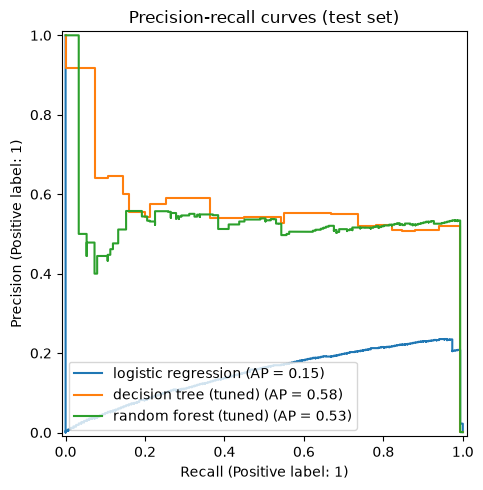

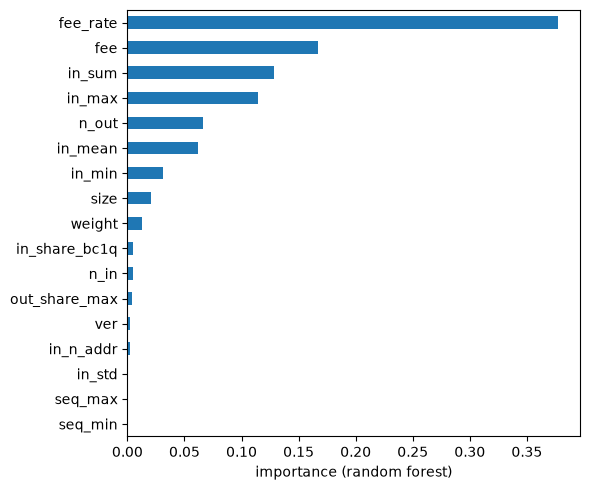

In [30]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt, os
os.makedirs("figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 5))
for name, proba in [("logistic regression", results["logreg"][2]),
                    ("decision tree (tuned)", final["tree"][2]),
                    ("random forest (tuned)", final["forest"][2])]:
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=ax)
ax.set_title("Precision-recall curves (test set)")
fig.tight_layout(); fig.savefig("figures/pr_curves.png", dpi=200)

imp = pd.Series(final["forest"][0].feature_importances_, index=feat).sort_values()
fig, ax = plt.subplots(figsize=(6, 5))
imp.plot.barh(ax=ax); ax.set_xlabel("importance (random forest)")
fig.tight_layout(); fig.savefig("figures/importance.png", dpi=200)
print(imp.sort_values(ascending=False).head(8).round(3))